In [1]:
import emcee
import numpy as np
import matplotlib.pyplot as plt
import copy
import importlib
import os
from astropy.io import fits
import scipy.constants as sc

In [16]:
inc = 47.178
PA = 342.094
mstar = 0.617
z_1 = 0.015
z_q = 0.505
Tb_10 = 122.497
Tb_q = -0.535
z_tap = 110.015
z_exp = 26.881
logtau_10 = 15.197
tau_q = -3.797
tau_tap = 125.099
tau_exp = 16.305
vlsr = 13960.621
dx = 0.011
dy = 0.003


pars = np.array([inc, PA, mstar, z_1, z_q, Tb_10, Tb_q, z_tap, z_exp, logtau_10, tau_q,tau_tap, tau_exp, vlsr, dx, dy])


theta = pars

In [17]:
def tapered_powerlaw(r, y_0, r_0, y_q, y_tap, y_exp):
    """Exponentially tapered power law."""
    return y_0 * (r / r_0)**y_q * np.exp(-(r / y_tap)**y_exp)


def z_f(r):
    """Emission surface of the front side of the disk."""
    return tapered_powerlaw(r, z_1, 1., z_q, z_tap, z_exp) # updated to 1'' 

def z_b(r):
    """Emission surface for the back side of the disk."""
    return -z_f(r)


def Tgas_Zallo(r): 
    return Tb_10 * (r / 10) ** Tb_q


def dV_Zallo(r): 
    mu=28.0
    T = Tgas_Zallo(r)
    return np.sqrt(2.0 * sc.k * T / (mu * (sc.m_p + sc.m_e)))

def tau(r):
    """Optical depth profile."""
    return tapered_powerlaw(r, 10**logtau_10, 10., tau_q, tau_tap, tau_exp)

/var/folders/cz/0k5dzksx1szdtp750kwzgszm0000gp/T/ipykernel_13788/1413917094.py:16: RuntimeWarning: divide by zero encountered in power
  return Tb_10 * (r / 10) ** Tb_q
/var/folders/cz/0k5dzksx1szdtp750kwzgszm0000gp/T/ipykernel_13788/1413917094.py:3: RuntimeWarning: divide by zero encountered in reciprocal
  return y_0 * (r / r_0)**y_q * np.exp(-(r / y_tap)**y_exp)


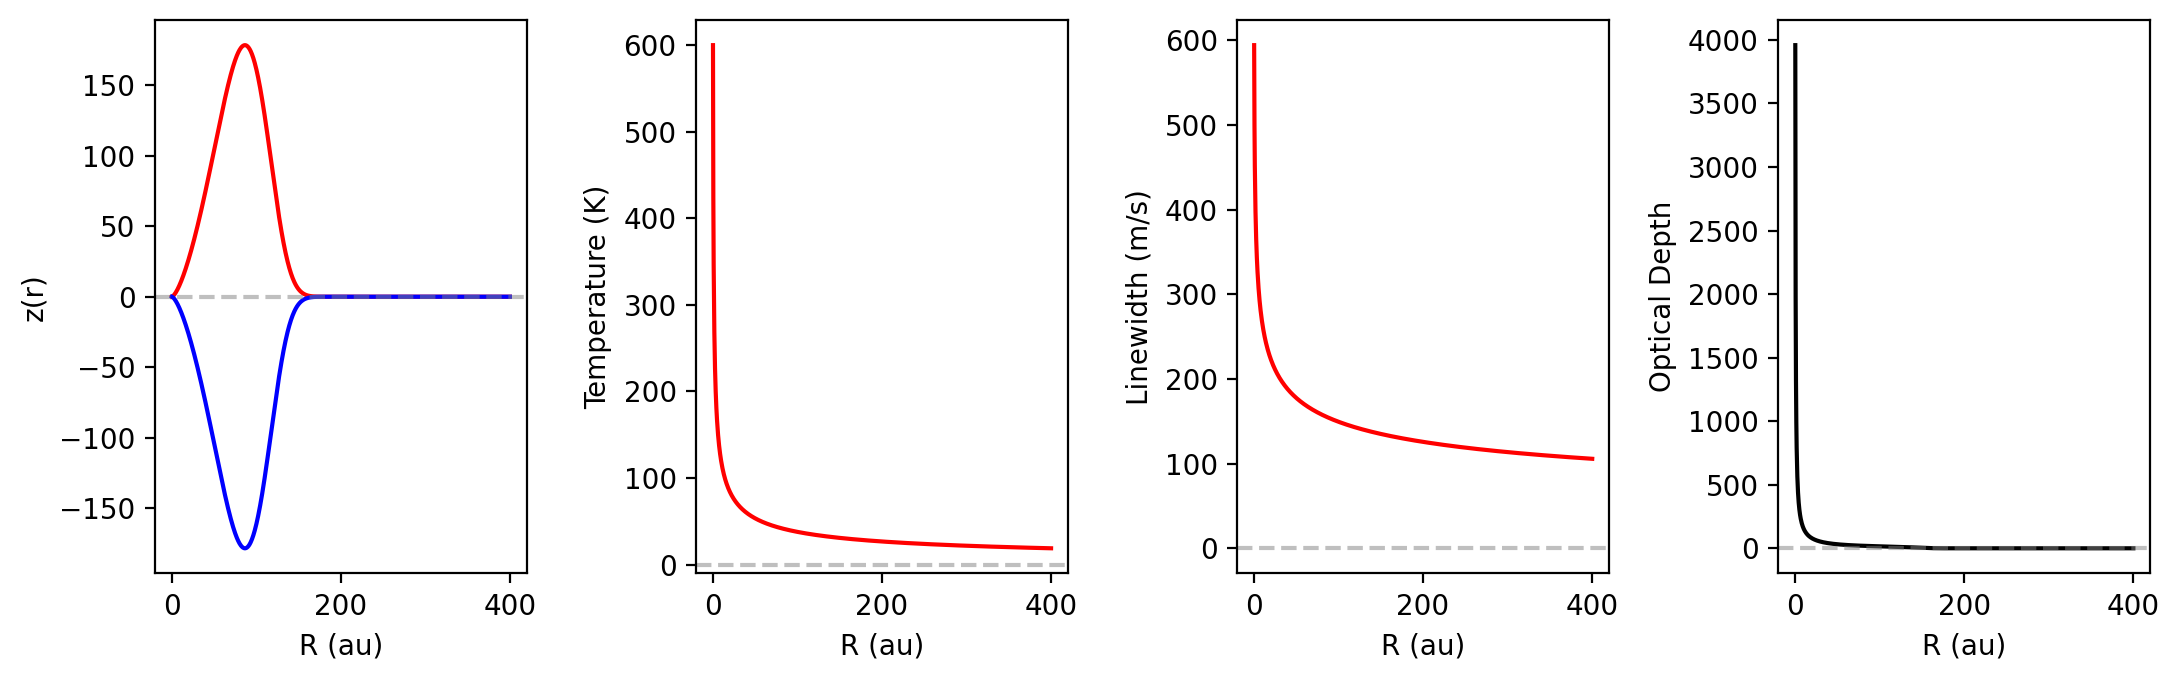

In [23]:

r = np.linspace(0, 400, 1000)  # radius in au

fig, axs = plt.subplots(1, 4, figsize=(11, 3.5), dpi=200)
axs = axs.flatten()

axs[0].plot(r, z_f(r), color="red", label="New")
axs[0].plot(r, z_b(r), color="blue")


# --- Temperature ---
axs[1].plot(r, Tgas_Zallo(r), color="red")


# --- Linewidth ---
axs[2].plot(r, dV_Zallo(r), color="red")


# --- Optical depth ---
axs[3].plot(r[1:], tau(r)[1:], color="black")


# --- Formatting ---
for ax in axs:
    #ax.set_xscale("log")
    ax.set_xlabel("R (au)")
    ax.axhline(0, color="gray", alpha=0.5, linestyle="--")

# Y-axis labels
axs[0].set_ylabel("z(r)")
axs[1].set_ylabel("Temperature (K)")
axs[2].set_ylabel("Linewidth (m/s)")
axs[3].set_ylabel("Optical Depth")

plt.tight_layout()
plt.show()

In [24]:
tau(r)[1:]

/var/folders/cz/0k5dzksx1szdtp750kwzgszm0000gp/T/ipykernel_13788/1413917094.py:3: RuntimeWarning: divide by zero encountered in reciprocal
  return y_0 * (r / r_0)**y_q * np.exp(-(r / y_tap)**y_exp)


array([3.95827075e+003, 1.97913537e+003, 1.31942358e+003, 9.89567687e+002,
       7.91654150e+002, 6.59711791e+002, 5.65467250e+002, 4.94783844e+002,
       4.39807861e+002, 3.95827075e+002, 3.59842795e+002, 3.29855896e+002,
       3.04482365e+002, 2.82733625e+002, 2.63884717e+002, 2.47391922e+002,
       2.32839456e+002, 2.19903930e+002, 2.08330039e+002, 1.97913537e+002,
       1.88489083e+002, 1.79921398e+002, 1.72098728e+002, 1.64927948e+002,
       1.58330830e+002, 1.52241183e+002, 1.46602620e+002, 1.41366812e+002,
       1.36492095e+002, 1.31942358e+002, 1.27686153e+002, 1.23695961e+002,
       1.19947598e+002, 1.16419728e+002, 1.13093450e+002, 1.09951965e+002,
       1.06980290e+002, 1.04165020e+002, 1.01494122e+002, 9.89567687e+001,
       9.65431890e+001, 9.42445416e+001, 9.20528081e+001, 8.99606988e+001,
       8.79615721e+001, 8.60493640e+001, 8.42185265e+001, 8.24639738e+001,
       8.07810356e+001, 7.91654148e+001, 7.76131517e+001, 7.61205911e+001,
       7.46843535e+001, 7

/var/folders/cz/0k5dzksx1szdtp750kwzgszm0000gp/T/ipykernel_13788/1413917094.py:16: RuntimeWarning: divide by zero encountered in power
  return Tb_10 * (r / 10) ** Tb_q
/var/folders/cz/0k5dzksx1szdtp750kwzgszm0000gp/T/ipykernel_13788/1413917094.py:3: RuntimeWarning: divide by zero encountered in reciprocal
  return y_0 * (r / r_0)**y_q * np.exp(-(r / y_tap)**y_exp)


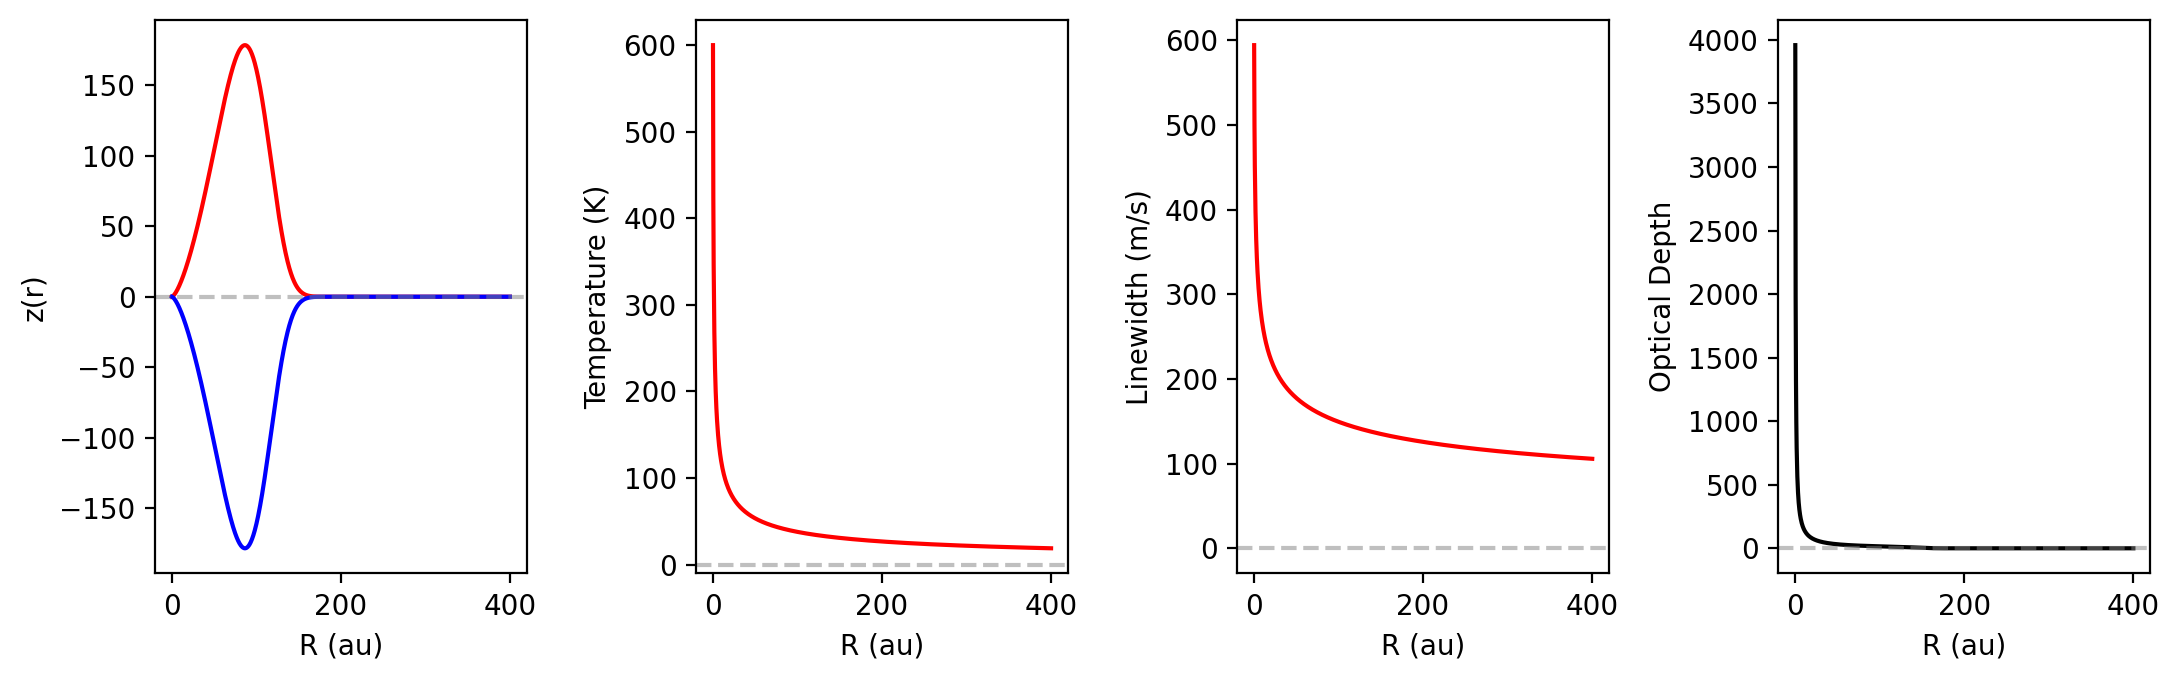

In [19]:
## DEMODISK PARAMETER 
theta = np.array([66.458, 162, 0.1 , 0.3 , 1.5, 
                  120, -0.5, 
                  110.083, 4.965, ## NEW
                  2.2, -1 , 
                  149.775, 9.984, 
                  12000,  0, 0])
#pars = theta

inc, PA, mstar, z_1, z_q, Tb_10, Tb_q, z_tap, z_exp, logtau_10, tau_q, tau_tap, tau_exp, vlsr, dx, dy = theta

## DEMODISK PARAMETER 
r = np.linspace(0, 400, 1000)  # radius in au

fig, axs = plt.subplots(1, 4, figsize=(11, 3.5), dpi=200)
axs = axs.flatten()

axs[0].plot(r, z_f(r), color="red", label="New")
axs[0].plot(r, z_b(r), color="blue")


# --- Temperature ---
axs[1].plot(r, Tgas_Zallo(r), color="red")


# --- Linewidth ---
axs[2].plot(r, dV_Zallo(r), color="red")


# --- Optical depth ---
axs[3].plot(r, tau(r), color="black")


# --- Formatting ---
for ax in axs:
    #ax.set_xscale("log")
    ax.set_xlabel("R (au)")
    ax.axhline(0, color="gray", alpha=0.5, linestyle="--")

# Y-axis labels
axs[0].set_ylabel("z(r)")
axs[1].set_ylabel("Temperature (K)")
axs[2].set_ylabel("Linewidth (m/s)")
axs[3].set_ylabel("Optical Depth")

plt.tight_layout()
plt.show()